# Figure 2 (dimensionless): Integral Feedback and Robust Perfect Adaptation

Same figure as `figure2.ipynb`, rebuilt on the dimensionless system of
`02-optimal-control-proper-time-improved.ipynb` instead of the dimensional
$(\alpha, \beta_1, \beta_2, \mu)$ model.

**Panel A** — Equations of the dimensionless integral feedback model:

$$\frac{dA}{dt} = \tau_r(q)\,q\,(1 - B)$$
$$\frac{dB}{dt} = \tau_r(q)\,(uA - B)$$

$A$ and $B$ are scaled by their untreated steady state, so $A^* = B^* = 1$
(the setpoint $\mu$ becomes $1$), and time is measured in units of the
relaxation time of the $A,B$ system, $\tau_r(q) = 1/\min|\mathrm{Re}\,\lambda|$.
What is left:

| symbol | meaning |
|---|---|
| $q = a b_1 / b_2^2$ | the only $A,B$ parameter; sets the damping ($q > 1/4$: underdamped) |
| $u \in [u_{\min}, u_{\max}] = [0.5, 1]$ | treatment, multiplies $b_1$; $u = 1$ is off treatment |
| $\rho$ | tumour growth rate while $B$ sits at its setpoint |
| $\alpha$ | drug strength |

The tumour $C$ rides along on top and never feeds back into $A$ or $B$:
$\dot C = C\,\rho\,\big(1 - \alpha\,f(1 - B)\big)$, where the kill term $f$ is
one-sided ($x^+$), a tolerance band, or linear ($x$).

**Notation clash.** In this notebook $\alpha$ is the *drug strength*
$\tilde c_2 / c_1$, following the optimal-control notebook. The $A$-gain called
$\alpha$ in `figure2.ipynb` is $a$ here and is absorbed into $q$. The full
mapping from the dimensional parameters is in the supplementary section.

**What changes relative to `figure2.ipynb`.** The switched parameter in every
panel is now the treatment $u$ (in place of $\beta_1$ in panel B and $\alpha$ in
panels E, G, F). Grey still means "soft spring", which is now "on treatment",
$u = u_{\min}$.

Notebook layout: panel B, panel D (fixed springs), panel E (adaptive
switching) + its zoomed inset, then panels G and F (resonance as treatment
under two kill models). Derivations and a numerical check of the mapping
live in the supplementary section at the bottom. Saved files carry the
prefix `figure2_dimless_` so they do not overwrite the dimensional figure.

In [1]:
"""Figure 2 (dimensionless) — shared imports and plotting style."""
import sys
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
from matplotlib.patches import Rectangle
from scipy.integrate import solve_ivp

sys.path.insert(0, '../src')
from rpa_control.style import set_style
from rpa_control.paths import save_fig

set_style()

In [2]:
# ======================================================================
# Plotting helpers (unchanged from figure2.ipynb)
# ======================================================================

def clean_ax(ax):
    ax.spines['right'].set_visible(False)
    ax.spines['top'].set_visible(False)

SHADE_COLOR = '0.93'   # grey == soft spring == on treatment (u = u_min)

def shade_spring(ax, t, ctrl, hard_val, soft_val):
    """Shade the time windows in which the soft spring is engaged.

    Grey means "soft spring" throughout this figure. The switched parameter is
    the treatment u, and the soft spring is u = u_min (k = q*u drops), so grey
    is also "on treatment": the post-switch span in panel B and the
    treated phases of the bang-bang schedule in panels E, G and F.
    """
    is_soft = np.isclose(ctrl, soft_val)
    changes = np.where(np.diff(is_soft.astype(int)) != 0)[0]
    boundaries = np.concatenate([[0], changes + 1, [len(t) - 1]])
    for j in range(len(boundaries) - 1):
        i0, i1 = boundaries[j], boundaries[j + 1]
        if is_soft[i0]:
            ax.axvspan(t[i0], t[i1], color=SHADE_COLOR, lw=0)

def spring_legend(hard_label, soft_label, figsize=(1.0, 3.2), fontsize=11):
    """Tall, narrow key for the background shading: white = hard, grey = soft.

    Two large blocks stacked in a column, each labelled inside. Its own
    figure, so it can sit beside a panel without eating axis space.
    """
    gap = 0.05                       # sliver of page between the two blocks
    fig, ax = plt.subplots(figsize=figsize)
    for y0, face, label in [(1 + gap, 'white', hard_label),
                            (0.0, SHADE_COLOR, soft_label)]:
        ax.add_patch(Rectangle((0, y0), 1, 1 - gap, facecolor=face,
                               edgecolor='0.8', lw=0.8))
        ax.text(0.5, y0 + (1 - gap) / 2, label, ha='center', va='center',
                fontsize=fontsize, linespacing=1.5)
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 2 + gap)
    ax.set_axis_off()
    fig.tight_layout(pad=0.05)
    return fig

KILL_COLOR = 'C3'   # B is painted in the tumour colour while C is shrinking
FREE_COLOR = 'C0'

def plot_kill_colored(ax, t, B, mask, lw=1.5, color_on=KILL_COLOR, color_off=FREE_COLOR):
    """Plot a trace as a two-colour line: `color_on` over the stretches where
    `mask` is True, `color_off` elsewhere. In panels G and F the mask is "C is
    shrinking"."""
    pts = np.array([t, B]).T.reshape(-1, 1, 2)
    segs = np.concatenate([pts[:-1], pts[1:]], axis=1)
    on = mask[:-1] | mask[1:]          # a boundary segment counts as active
    lc = LineCollection(segs, colors=[color_on if o else color_off for o in on],
                        linewidths=lw, capstyle='round')
    ax.add_collection(lc)
    ax.set_xlim(t.min(), t.max())
    ax.autoscale_view()
    return lc

def rk4_step(f, y, dt):
    k1 = f(y); k2 = f(y + 0.5*dt*k1)
    k3 = f(y + 0.5*dt*k2); k4 = f(y + dt*k3)
    return y + (dt/6.0) * (k1 + 2*k2 + 2*k3 + k4)

# ======================================================================
# Dimensionless model
# ======================================================================

EQ = 1.0                   # setpoint of B (mu / mu)
U_MIN, U_MAX = 0.5, 1.0    # u = 1: off treatment; u = 0.5: drug halves b1

def tau_r(q):
    """Relaxation time of the A,B system (u = 1) in tau = b2*t units:
    1 / min|Re(lambda)| for lambda^2 + lambda + q = 0. Same as t_relax in
    the optimal-control notebook."""
    return 2.0 if q > 0.25 else 2.0 / (1.0 - np.sqrt(1.0 - 4.0*q))

def to_dimensionless(a, b1, b2, mu, c1, c2, k=1):
    """Map the dimensional model (A-gain a, b1, b2, mu, c1, c2) of figure2.ipynb
    onto (q, rho, alpha). Also returns the scales: t_hat = t * time_scale,
    A_tilde = A / A_scale, B_tilde = B / B_scale. k = 1 for linear kill terms,
    2 for quadratic."""
    q = a * b1 / b2**2
    tr = tau_r(q)
    return dict(q=q, rho=tr * c1 / b2, alpha=c2 * mu**k / c1,
                time_scale=b2 / tr, A_scale=b2 * mu / b1, B_scale=mu)

def adaptive_u(A, B, u_hard, u_soft, eq=EQ):
    """Resonant treatment: pump energy into the A,B oscillator.

    Write u = u_bar + delta*s with s = +/-1. About the mid fixed point
    (A, B) = (1/u_bar, 1), E = q*(B - 1)^2 + u_bar*(A - 1/u_bar)^2 obeys,
    exactly,
        dE/dt = 2*tau_r*q * [ -(B - 1)^2 + delta * s * (B - 1) * A ],
    so E rises fastest with s = sign((B - 1) * A): off treatment (hard)
    while (B - 1)*A > 0, on treatment (soft) otherwise. u multiplies A in
    dB/dt, so A sets the phase together with B. This is the bang-bang law of
    the PMP notebook (u_max iff lambda_2*A < 0) with lambda_2 ~ -(B - 1).
    A tie (B exactly at the setpoint) starts treatment.
    """
    return u_hard if (B - eq) * A > 0 else u_soft

# ======================================================================
# Shared parameters
# ======================================================================

T = 10.0       # simulation horizon of panels E/G/F (relaxation times)
dt = 0.001     # RK4 timestep for adaptive simulations (q = 100 rings fast)

# --- Panel B: single parameter switch ---
#     This is exactly panel B of figure2.ipynb (a = 1, b1 = 2, b2 = 1, mu = 1,
#     c1 = 0.1, c2 = 1, b1 halved at t = 5 of 20), mapped through
#     to_dimensionless: q = 2, rho = 0.2, alpha = 10, and time runs at half speed
#     (tau_r = 2). Halving b1 is the step u: 1 -> 0.5. Checked numerically
#     in the SI.
_B_MAP = to_dimensionless(a=1.0, b1=2.0, b2=1.0, mu=1.0, c1=0.1, c2=1.0)
PANEL_B = dict(
    q=_B_MAP['q'], rho=_B_MAP['rho'], alpha=_B_MAP['alpha'],
    u_base=U_MAX, u_pert=U_MIN,
    t_switch=5.0 * _B_MAP['time_scale'],
    t_end=20.0 * _B_MAP['time_scale'],
)

# --- Panel D: hard vs soft spring, fixed u ---
#     q is the dimensionless spring (k = q*u in tau = b2*t units, unit damping),
#     so the springs are two values of q at u = 1. They are the q values of
#     the dimensional panel D (a = b2 = 1, b1 = 0.1 vs 2), so the damping ratios
#     1/(2*sqrt(q*u)) are the same as there. The start is pinned in
#     (B, dB/dt) so both curves leave one initial state; A0 follows.
PANEL_D = dict(
    u=U_MAX, rho=PANEL_B['rho'], alpha=PANEL_B['alpha'],
    q_hard=2.0, q_soft=0.1,
    B0=2.0, Bdot0=-1.5, C0=1.0,
)

def panel_d_x0(p, q):
    """[A, B, C] giving the (B0, Bdot0) of PANEL_D at this q."""
    return [(p['Bdot0'] / tau_r(q) + p['B0']) / p['u'], p['B0'], p['C0']]

# --- Panel E: adaptive switching drives resonance ---
#     Switching the treatment u in [0.5, 1] by adaptive_u. Energy is pumped in
#     only if q is large enough to beat the damping (roughly q > 30 for this
#     range of u), so we use q = 100, the most underdamped value of the
#     optimal-control notebook, where PMP itself finds the resonant strategy.
#     Start from the untreated steady state A = B = 1, as in that notebook.
PANEL_E = dict(
    q=100.0,
    u_hard=U_MAX, u_soft=U_MIN,
    rho=0.1, alpha=10.0,
    x0=[1.0, 1.0, 1.0],
)

# --- Panels G and F: resonance as treatment. Same A/B dynamics as panel E,
#     different tumour parameters. alpha = 0.1 is c2*mu/c1 of the dimensional
#     panels (c1 = 1, c2 = 0.1), so C shrinks only once the kill term exceeds
#     1/alpha = 10. G is one-sided (kill whenever B < 1), F uses a tolerance
#     band (kill only once |B - 1| exceeds `radius`).
PANEL_G = dict(PANEL_E, rho=1.0, alpha=0.1, radius=0.0)
PANEL_F = dict(PANEL_E, rho=1.0, alpha=0.1, radius=5.0)

# ======================================================================
# ODE right-hand sides
# ======================================================================

def penalty_below(B, radius=0.0, eq=EQ):
    """One-sided kill term f(1 - B) = (1 - B)^+, shifted by radius."""
    return np.maximum((eq - B) - radius, 0.0)

def penalty_band(B, radius=0.0, eq=EQ):
    """Two-sided kill term: active once B leaves the band 1 +/- radius."""
    return np.maximum(np.abs(eq - B) - radius, 0.0)

def shrink_mask(B, p, penalty=penalty_below):
    """True where dC/dt < 0, i.e. alpha * f(1 - B) > 1 (rho > 0).
    Stricter than "kill term on": C keeps growing until |B - 1| exceeds
    radius + 1/alpha."""
    return p['alpha'] * penalty(B, p.get('radius', 0.0)) > 1.0

def minimal_rhs(y, q, u, rho, alpha, radius=0.0, penalty=penalty_below):
    """Dimensionless integral feedback (A, B) plus a tumour C that shrinks
    while alpha * f(1 - B) > 1. C does not feed back into A or B, so B(t) is
    identical for every choice of `penalty`, rho and alpha."""
    A, B, C = y
    tr = tau_r(q)
    return np.array([tr * q * (EQ - B),
                     tr * (u * A - B),
                     C * rho * (1.0 - alpha * penalty(B, radius))])

# ======================================================================
# Simulation runners
# ======================================================================

def run_panel_B(penalty=penalty_below, radius=0.0):
    """Start at steady state (A = B = 1), step u from 1 to 0.5 at t_switch,
    watch B return to 1 while A settles at 1/u = 2."""
    p = PANEL_B
    x0_ss = [EQ / p['u_base'], EQ, 1.0]

    def phase(t0, t1, u, y0):
        return solve_ivp(
            lambda t_, y: minimal_rhs(y, p['q'], u, p['rho'], p['alpha'],
                                      radius=radius, penalty=penalty).tolist(),
            [t0, t1], y0, dense_output=True, max_step=0.025)

    sol1 = phase(0, p['t_switch'], p['u_base'], x0_ss)
    sol2 = phase(p['t_switch'], p['t_end'], p['u_pert'], sol1.sol(p['t_switch']))

    t1 = np.linspace(0, p['t_switch'], 250)
    t2 = np.linspace(p['t_switch'], p['t_end'], 500)[1:]
    y = np.concatenate([sol1.sol(t1), sol2.sol(t2)], axis=1)
    return dict(t=np.concatenate([t1, t2]), A=y[0], B=y[1], C=y[2],
                t_switch=p['t_switch'])

def run_adaptive(p, penalty=penalty_below):
    """Bang-bang treatment u driven by the sign of (B - 1)*A: pumps energy
    into the A,B oscillator (see adaptive_u)."""
    radius = p.get('radius', 0.0)
    n_steps = int(round(T / dt))
    t_arr = np.linspace(0, T, n_steps + 1)
    y = np.zeros((n_steps + 1, 3)); y[0] = p['x0']
    u_t = np.zeros(n_steps + 1)
    for i in range(n_steps):
        A, B, C = y[i]
        ui = adaptive_u(A, B, p['u_hard'], p['u_soft'])
        u_t[i] = ui
        y[i+1] = rk4_step(
            lambda y_: minimal_rhs(y_, p['q'], ui, p['rho'], p['alpha'],
                                   radius=radius, penalty=penalty),
            y[i], dt)
    u_t[-1] = u_t[-2]
    return dict(t=t_arr, y=y, ctrl=u_t, u=u_t)

# ======================================================================
# Run the main-text simulations
# ======================================================================
data_B = run_panel_B()                                   # panel B
data_E = run_adaptive(PANEL_E)                           # panel E (+ inset)
data_G = run_adaptive(PANEL_G)                           # panel G, one-sided kill
data_F = run_adaptive(PANEL_F, penalty=penalty_band)     # panel F, tolerance band

print("Simulations complete: data_B, data_E, data_G, data_F.")
print("Panel B maps to q = {q:g}, rho = {rho:g}, alpha = {alpha:g}, "
      "t_switch = {t_switch:g}, t_end = {t_end:g}".format(**PANEL_B))

Simulations complete: data_B, data_E, data_G, data_F.
Panel B maps to q = 2, rho = 0.2, alpha = 10, t_switch = 2.5, t_end = 10


**Panel B** — A fixed dose ($u$: $1 \to 0.5$, i.e. $b_1$ halved) fails to change
$B$'s steady state; $A$ absorbs it, settling at $1/u = 2$:

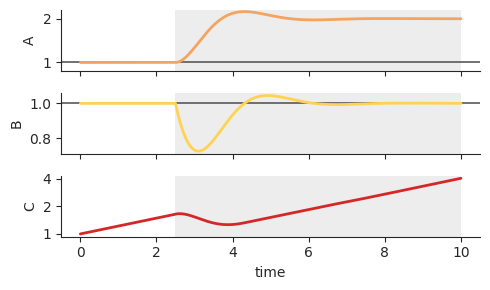

Figure saved to /home/amir/RL/autodiff-control/plots/figure2_dimless_B.pdf


In [3]:
# Panel B: standalone plot — A(t), B(t), C(t)

lw = 2

fig, axs = plt.subplots(3, 1, figsize=(5, 3.0), sharex=True,)

# A(t)
ax = axs[0]
ax.plot(data_B['t'], data_B['A'], lw=lw, color='sandybrown')
ax.axhline(EQ / PANEL_B['u_base'], color='0.35', lw=1.2, zorder=1)  # pre-switch steady state
ax.set_ylabel('A')
ax.set_ylim(0.8, 2.2)

# B(t)
ax = axs[1]
ax.plot(data_B['t'], data_B['B'], lw=lw, color='#ffd351')
ax.axhline(EQ, color='0.35', lw=1.2, zorder=1)  # setpoint
ax.set_ylabel('B')

# C(t) - Cancer in log scale
ax = axs[2]
ax.plot(data_B['t'], data_B['C'], lw=lw, color='tab:red')
ax.set_yscale('log')
ax.set_ylabel('C')
ax.set_xlabel('time')
ax.set_yticks([1, 2, 4])
ax.set_yticklabels([1, 2, 4])
# On a log axis spanning less than a decade, matplotlib labels the minor
# ticks too: drop them.
ax.minorticks_off()

for ax in axs:
    ax.axvspan(data_B['t_switch'], data_B['t'].max(), color=SHADE_COLOR, lw=0, zorder=-1)
    sns.despine(ax=ax)


plt.tight_layout()
plt.show()

save_fig(fig, 'figure2_dimless_B.pdf')

**Panel C** — The integral feedback system is equivalent to a damped harmonic oscillator.

For constant $u$, eliminating $A$ yields a single second-order ODE. In
$\tau = b_2 t$ units (before the relaxation rescaling) it reads

$$B'' + B' + q\,u\,(B - 1) = 0,$$

so with $x = B - 1$:

| Physical quantity | Parameter |
|---|---|
| Mass $m$ | $1$ |
| Damping $c$ | $1$ |
| **Spring constant $k$** | $q\,u$ |

Damping ratio $\zeta = 1/(2\sqrt{q u})$. Treatment ($u_{\min}$) softens the
spring; $q$ sets how stiff it is to begin with. In the relaxation-time units
used for all plots, every coefficient is multiplied through by $\tau_r(q)$
(see SI), which changes the clock but not the shape of the response.

**Panel D** — With a *fixed* spring, $B$ always converges to $1$; only the
approach differs (soft $q = 0.1$: overdamped; hard $q = 2$: ringing).

Because time is in units of the relaxation time $\tau_r(q)$, both springs
settle on the *same* timescale here. In `figure2.ipynb` the soft spring was also
visibly slower; in these units that difference is removed by construction,
and what remains is the shape of the approach.

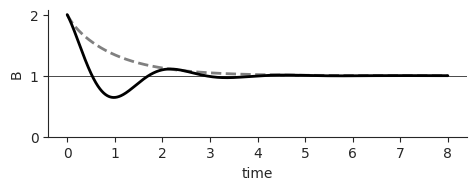

Figure saved to /home/amir/RL/autodiff-control/plots/figure2_dimless_panelD.pdf


<Figure size 220x90 with 0 Axes>

Figure saved to /home/amir/RL/autodiff-control/plots/figure2_dimless_panelD_legend.pdf


In [4]:
# Panel D: fixed springs — both converge to the setpoint.
# T_springs is local and does NOT affect T or any other panel's data.
T_springs = 8.0
t_springs = np.linspace(0, T_springs, 4000)

p = PANEL_D
springs = [
    ('soft', p['q_soft'], 'grey'),
    ('hard', p['q_hard'], 'black'),
]

# Store results for reuse in composite figure
data_springs = {'t': t_springs, 'curves': []}
for name, q, color in springs:
    sol = solve_ivp(
        lambda t_, y, q=q: minimal_rhs(y, q, p['u'], p['rho'], p['alpha']).tolist(),
        [0, T_springs], panel_d_x0(p, q), dense_output=True, max_step=0.01)
    data_springs['curves'].append((name, q, color, sol.sol(t_springs)[1]))

fig, ax_B = plt.subplots(1, 1, figsize=(5, 2))
ax = ax_B

for name, q, color, B in data_springs['curves']:
    if name == 'soft':
        ax_B.plot(t_springs, B, lw=2.0, color=color, linestyle='--',
                  label=f'soft spring ($q = {q:g}$)')
    elif name == 'hard':
        ax_B.plot(t_springs, B, lw=2.0, color=color,
                  label=f'hard spring ($q = {q:g}$)')

ax_B.axhline(EQ, color='black', ls='-', lw=0.5, zorder=-1, label='setpoint')
sns.despine(ax=ax)
ax.set_ylabel(r'B')
ax.set_xlabel(r'time')
ax.set_ylim(bottom=0)

plt.tight_layout()
plt.show()

save_fig(fig, 'figure2_dimless_panelD.pdf')

# Legend as its own figure, so it can be placed beside the panel.
handles, labels = ax_B.get_legend_handles_labels()
fig_leg = plt.figure(figsize=(2.2, 0.9))
fig_leg.legend(handles, labels, frameon=False, loc='center', fontsize=11)
plt.show()

save_fig(fig_leg, 'figure2_dimless_panelD_legend.pdf')

**Panel E** — Switching the treatment $u$ on the sign of $(B-1)\,A$ pumps energy
into the oscillator instead of damping it: $B$ resonates away from the
setpoint. $u$ multiplies $A$ in $\dot B$, so the controller watches $B$ and $A$
together (derivation in `adaptive_u` and the SI). With $u \in [0.5, 1]$ the
pumping only beats the damping for large $q$; we use $q = 100$.

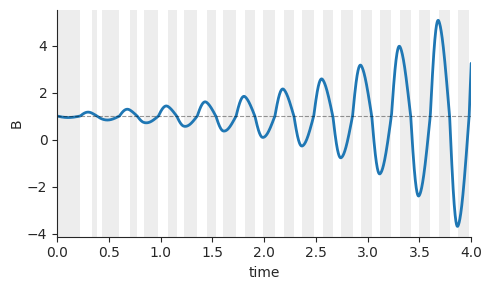

Figure saved to /home/amir/RL/autodiff-control/plots/figure2_dimless_panelE.pdf


In [5]:
# Panel E: adaptive switching — B(t)
# Illustrative: only the first stretch (t <= T_E), so the growing swing
# around the setpoint reads clearly on a linear axis. Same run as panels G
# and F, which show the full horizon T.
T_E = 4.0
show = data_E['t'] <= T_E
t_E, B_E, u_E = data_E['t'][show], data_E['y'][show, 1], data_E['u'][show]

fig, ax = plt.subplots(1, 1, figsize=(5, 3))
ax_B = ax

shade_spring(ax_B, t_E, u_E, PANEL_E['u_hard'], PANEL_E['u_soft'])

ax_B.plot(t_E, B_E, lw=2, color='C0', label='Adaptive switching')
ax_B.axhline(EQ, color='black', ls='--', lw=0.8, alpha=0.4, label='setpoint')
ax_B.set_xlim(0, T_E)
ax_B.set_ylabel('B')
ax.set_xlabel('time')

sns.despine(ax=ax)
ax_B.yaxis.set_label_coords(-0.08, 0.5)

plt.tight_layout()
plt.show()

save_fig(fig, 'figure2_dimless_panelE.pdf')

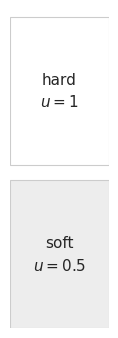

Figure saved to /home/amir/RL/autodiff-control/plots/figure2_dimless_E_legend.pdf


In [6]:
# Key for the grey background in panel E: grey == soft spring == on treatment.
# Values come from PANEL_E, so the key cannot drift from the simulation.
# Panels G and F inherit PANEL_E, so the same key serves them.
fig = spring_legend(
    hard_label=f"hard\n$u = {PANEL_E['u_hard']:g}$",
    soft_label=f"soft\n$u = {PANEL_E['u_soft']:g}$")
plt.show()

save_fig(fig, 'figure2_dimless_E_legend.pdf')

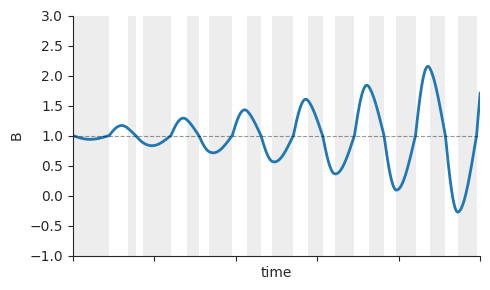

Figure saved to /home/amir/RL/autodiff-control/plots/figure2_dimless_panelE_inset.pdf


In [7]:
# Inset for the resonance panels: zoom of B(t) over the first stretch
T_INSET = 2.5
fig, ax = plt.subplots(1, 1, figsize=(5, 3))
ax_B = ax

shade_spring(ax_B, data_E['t'], data_E['u'],
             PANEL_E['u_hard'], PANEL_E['u_soft'])

ax_B.plot(data_E['t'], data_E['y'][:, 1], lw=2, color='C0', label='Adaptive switching')
ax_B.axhline(EQ, color='black', ls='--', lw=0.8, alpha=0.4, label='setpoint')
ax_B.set_ylabel('B')

clean_ax(ax_B)
plt.setp(ax_B.get_xticklabels(), visible=False)

ax.set_xlabel('time')
ax.set_xlim(0, T_INSET)
ax.set_ylim(-1, 3)

plt.tight_layout()
plt.show()

save_fig(fig, 'figure2_dimless_panelE_inset.pdf')

# As treatment

**Panels G and F** — Resonance as treatment. Driving $B$ away from its setpoint
shrinks the tumour $C$. $B(t)$ is identical in both; only the kill term differs:

| | kill term $f$ | file |
|---|---|---|
| **G** | one-sided: $(1 - B)^+$, active whenever $B < 1$ | `figure2_dimless_panelG.pdf` |
| **F** | tolerance band: $(\lvert 1 - B\rvert - 5)^+$ | `figure2_dimless_panelF.pdf` |

In both panels $B$ is drawn in red over exactly the stretches where $C$ is
shrinking, i.e. where $\alpha\,f > 1$. That threshold is stricter than "kill
term on": with $\alpha = 0.1$, $C$ only falls once $\lvert B - 1\rvert$ exceeds
$\text{radius} + 1/\alpha = \text{radius} + 10$.

**The kill terms** — $\dot C = C\,g(B)$ with $g(B) = \rho\,\big(1 - \alpha\,f(1 - B)\big)$,
$\rho = 1$, $\alpha = 0.1$. Growth is capped at $\rho$ but killing is unbounded
and linear in the deviation, so the tumour collapses fast once $B$ resonates.
One small panel per treatment shows $f$ alone, red where $f > 1/\alpha$ (dashed
line), i.e. where $g < 0$; those stretches start at $B = 1 \pm (\text{radius} + 1/\alpha)$.

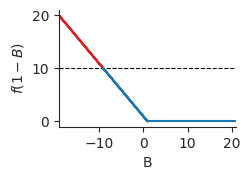

Figure saved to /home/amir/RL/autodiff-control/plots/figure2_dimless_growth_G.pdf


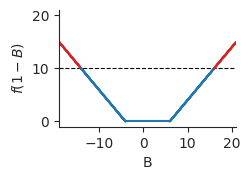

Figure saved to /home/amir/RL/autodiff-control/plots/figure2_dimless_growth_F.pdf


In [8]:
# The kill term f(1 - B) of each treatment panel, plotted on its own.
# Built from the same penalty helpers and PANEL_* dicts the simulations use,
# so these cannot drift from the dynamics. Red wherever C is shrinking,
# i.e. where alpha * f > 1, so f > 1/alpha (dashed line).
B_grid = EQ + np.linspace(-20, 20, 2001)   # centred on the setpoint

panels = [
    ('G', 'one-sided kill', PANEL_G, penalty_below, 'figure2_dimless_growth_G.pdf'),
    ('F', 'tolerance band', PANEL_F, penalty_band,  'figure2_dimless_growth_F.pdf'),
]

for name, subtitle, p, pen, fname in panels:
    f_vals = pen(B_grid, p['radius'])
    f_star = 1.0 / p['alpha']              # kill balances growth: g = 0

    fig, ax = plt.subplots(1, 1, figsize=(2.6, 1.9))

    ax.axhline(f_star, color='black', lw=0.8, ls='--', zorder=1)
    plot_kill_colored(ax, B_grid, f_vals, f_vals > f_star)

    ax.set_xlabel('B')
    ax.set_ylabel(r'$f(1 - B)$')
    ax.set_xlim(B_grid.min(), B_grid.max())
    ax.set_ylim(-1, 21)
    sns.despine(ax=ax)

    plt.tight_layout()
    plt.show()

    save_fig(fig, fname)

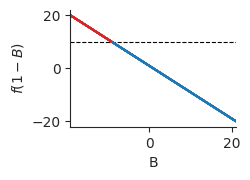

Figure saved to /home/amir/RL/autodiff-control/plots/figure2_dimless_growth_linear.pdf


In [9]:
# The purely linear kill term f(1 - B) = 1 - B (g_2 of the optimal-control
# notebook), for comparison with the rectified versions above. It goes
# negative above the setpoint (B > 1), where it boosts growth instead of killing.
p = PANEL_G
f_vals = EQ - B_grid
f_star = 1.0 / p['alpha']

fig, ax = plt.subplots(1, 1, figsize=(2.6, 1.9))

ax.axhline(f_star, color='black', lw=0.8, ls='--', zorder=1)
plot_kill_colored(ax, B_grid, f_vals, f_vals > f_star)

ax.set_xlabel('B')
ax.set_ylabel(r'$f(1 - B)$')
ax.set_xlim(B_grid.min(), B_grid.max())
sns.despine(ax=ax)

plt.tight_layout()
plt.show()

save_fig(fig, 'figure2_dimless_growth_linear.pdf')

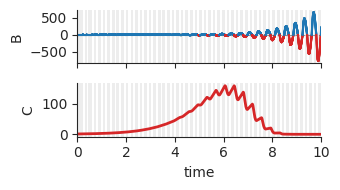

Figure saved to /home/amir/RL/autodiff-control/plots/figure2_dimless_panelG.pdf


In [10]:
# Panel G: resonance as treatment — B(t) on top, tumour C(t) below.
# One-sided kill: C shrinks once B dips below 1 - 1/alpha.
# B is painted red over the stretches where C is actually falling.
dG = data_G
B, C = dG['y'][:, 1], dG['y'][:, 2]
shrinking = shrink_mask(B, PANEL_G)

fig, axs = plt.subplots(nrows=2, ncols=1, figsize=(3.5, 2.0), sharex=True)

ax = axs[0]
plot_kill_colored(ax, dG['t'], B, shrinking)
ax.axhline(EQ, color='black', ls='--', lw=0.8, alpha=0.4, zorder=1.5)
ax.set_ylabel('B')

ax = axs[1]
ax.plot(dG['t'], C, lw=2, color=KILL_COLOR)
ax.set_ylabel('C')
ax.set_xlabel('time')

for ax in axs:
    shade_spring(ax, dG['t'], dG['u'], PANEL_G['u_hard'], PANEL_G['u_soft'])
    sns.despine(ax=ax)

plt.tight_layout()
plt.show()

save_fig(fig, 'figure2_dimless_panelG.pdf')

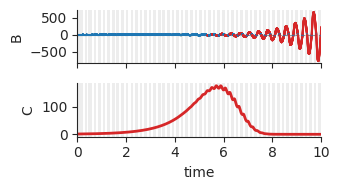

Figure saved to /home/amir/RL/autodiff-control/plots/figure2_dimless_panelF.pdf


In [11]:
# Panel F: same resonance, tolerance-band kill — C only shrinks once
# |B - 1| exceeds PANEL_F['radius'] + 1/alpha, so resonance must build real
# amplitude before it treats. B is painted red where C is actually falling.
dF = data_F
B, C = dF['y'][:, 1], dF['y'][:, 2]
shrinking = shrink_mask(B, PANEL_F, penalty_band)

fig, axs = plt.subplots(nrows=2, ncols=1, figsize=(3.5, 2.0), sharex=True)

ax = axs[0]
plot_kill_colored(ax, dF['t'], B, shrinking)
ax.axhline(EQ, color='black', ls='--', lw=0.8, alpha=0.4, zorder=1.5)
ax.set_ylabel('B')

ax = axs[1]
ax.plot(dF['t'], C, lw=2, color=KILL_COLOR)
ax.set_ylabel('C')
ax.set_xlabel('time')

for ax in axs:
    shade_spring(ax, dF['t'], dF['u'], PANEL_F['u_hard'], PANEL_F['u_soft'])
    sns.despine(ax=ax)

plt.tight_layout()
plt.show()

save_fig(fig, 'figure2_dimless_panelF.pdf')

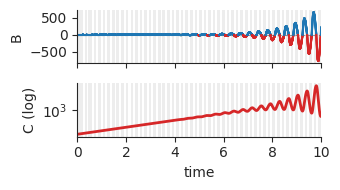

Figure saved to /home/amir/RL/autodiff-control/plots/figure2_dimless_panel_linear.pdf


In [12]:
# Same resonance, purely linear kill term f(1 - B) = 1 - B.
# Same B(t) as panels G and F; only C differs. The kill term is signed, so
# swings above 1 boost growth by as much as swings below 1 kill, and C rides
# up and down by orders of magnitude instead of collapsing. Log axis for C.
def penalty_linear(B, radius=0.0, eq=EQ):
    """Signed kill term: kills below eq, boosts growth above it."""
    return (eq - B) - radius

dL = run_adaptive(PANEL_G, penalty=penalty_linear)
B, C = dL['y'][:, 1], dL['y'][:, 2]
shrinking = shrink_mask(B, PANEL_G, penalty_linear)

fig, axs = plt.subplots(nrows=2, ncols=1, figsize=(3.5, 2.0), sharex=True)

ax = axs[0]
plot_kill_colored(ax, dL['t'], B, shrinking)
ax.axhline(EQ, color='black', ls='--', lw=0.8, alpha=0.4, zorder=1.5)
ax.set_ylabel('B')

ax = axs[1]
ax.semilogy(dL['t'], C, lw=2, color=KILL_COLOR)
ax.set_ylabel('C (log)')
ax.set_xlabel('time')

for ax in axs:
    shade_spring(ax, dL['t'], dL['u'], PANEL_G['u_hard'], PANEL_G['u_soft'])
    sns.despine(ax=ax)

plt.tight_layout()
plt.show()

save_fig(fig, 'figure2_dimless_panel_linear.pdf')

# Supplementary:

### SI: From the dimensional model to the dimensionless one

Dimensional model (as in the optimal-control notebook; $a$ is the $\alpha$ of `figure2.ipynb`):

$$\dot A = a(\mu - B), \qquad \dot B = b_1 u A - b_2 B, \qquad \dot C = C\,\big(c_1 - c_2 f(\mu - B)\big)$$

**States.** Scale by the untreated steady state: $\tilde B = B/\mu$,
$\tilde A = A / (b_2\mu/b_1)$.

**Time.** First $\tau = b_2 t$, which leaves $\tilde A' = q(1 - \tilde B)$,
$\tilde B' = u\tilde A - \tilde B$ with $q = a b_1 / b_2^2$. The linearisation at
$u = 1$ has eigenvalues $\lambda = \tfrac{1}{2}\big(-1 \pm \sqrt{1 - 4q}\big)$, so
the relaxation time is $\tau_r(q) = 2$ for $q > 1/4$ and
$2 / (1 - \sqrt{1 - 4q})$ otherwise. Then $\hat t = \tau / \tau_r(q)$, which
multiplies every right-hand side by $\tau_r(q)$.

**Tumour.** With $\tilde c_2 = c_2\mu^k$ ($k$ = power of $f$):
$\rho = \tau_r(q)\,c_1 / b_2$ and $\alpha = \tilde c_2 / c_1$.

| dimensional (`figure2.ipynb`) | dimensionless (this notebook) |
|---|---|
| $\alpha,\ \beta_1,\ \beta_2$ | $q = \alpha\beta_1/\beta_2^2$ |
| $\mu$ | $1$ |
| $\beta_1 \to \beta_1 \cdot u$ | $u$ |
| $c_1$ | $\rho = \tau_r(q)\,c_1/\beta_2$ |
| $c_2$ | $\alpha_{\text{drug}} = c_2\mu^k/c_1$ |
| $t$ | $\hat t = \beta_2\,t/\tau_r(q)$ |

Panel B is the one panel whose dimensional and dimensionless versions are the
*same* experiment ($b_1$ halved = $u$ from $1$ to $0.5$); the cell below checks
the mapping by running the dimensional panel B and rescaling it.

In [13]:
# Check: dimensional panel B of figure2.ipynb, rescaled, must equal data_B.
a_, b1_, b2_, mu_, c1_, c2_ = 1.0, 2.0, 1.0, 1.0, 0.1, 1.0
m = to_dimensionless(a_, b1_, b2_, mu_, c1_, c2_)

def dim_rhs(t_, y, b1):
    A, B, C = y
    return [a_ * (mu_ - B), b1 * A - b2_ * B, C * (c1_ - c2_ * max(mu_ - B, 0.0))]

t_sw, t_end = 5.0, 20.0
y_ss = [b2_ * mu_ / b1_, mu_, 1.0]
s1 = solve_ivp(dim_rhs, [0, t_sw], y_ss, args=(b1_,), dense_output=True,
               rtol=1e-9, atol=1e-11)
s2 = solve_ivp(dim_rhs, [t_sw, t_end], s1.sol(t_sw), args=(b1_ * U_MIN,),
               dense_output=True, rtol=1e-9, atol=1e-11)

t_dim = data_B['t'] / m['time_scale']           # same instants, dimensional clock
y_dim = np.where(t_dim <= t_sw, s1.sol(np.minimum(t_dim, t_sw)),
                 s2.sol(np.maximum(t_dim, t_sw)))
err_A = np.max(np.abs(y_dim[0] / m['A_scale'] - data_B['A']))
err_B = np.max(np.abs(y_dim[1] / m['B_scale'] - data_B['B']))
err_C = np.max(np.abs(np.log(y_dim[2]) - np.log(data_B['C'])))
print(f"max |error|  A: {err_A:.1e}   B: {err_B:.1e}   log C: {err_C:.1e}")
assert max(err_A, err_B, err_C) < 1e-3

max |error|  A: 1.2e-09   B: 7.0e-10   log C: 2.7e-06


### SI: Derivation — the dimensionless system as a damped mass-spring

**Given system** (constant $u$, $\hat t$ units):

$$\dot A = \tau_r(q)\,q\,(1 - B) \tag{1}$$

$$\dot B = \tau_r(q)\,(uA - B) \tag{2}$$

**Step 1:** Differentiate Eq. 2: $\ddot B = \tau_r(q)\,(u\dot A - \dot B)$.

**Step 2:** Substitute Eq. 1: $\ddot B = \tau_r(q)^2\,q\,u\,(1 - B) - \tau_r(q)\,\dot B$.

**Step 3:** With $x = B - 1$:

$$\boxed{\ddot x + \tau_r(q)\,\dot x + \tau_r(q)^2\,q\,u\,x = 0}$$

| Physical quantity | $\hat t$ units | $\tau = b_2 t$ units |
|---|---|---|
| Mass $m$ | $1$ | $1$ |
| Damping $c$ | $\tau_r(q)$ | $1$ |
| Spring constant $k$ | $\tau_r(q)^2\,q\,u$ | $q\,u$ |

The two columns are the same oscillator on different clocks; the damping
ratio $\zeta = 1/(2\sqrt{qu})$ is the same in both. The equilibrium is $B = 1$
for every $q$ and $u$ (robust perfect adaptation); $A$ settles at $1/u$.

### SI: Why the switching law pumps energy

Write $u = \bar u + \delta s$ with $\bar u = (u_{\min} + u_{\max})/2$,
$\delta = (u_{\max} - u_{\min})/2$, $s = \pm 1$. Measuring from the mid fixed
point, $x = B - 1$, $y = A - 1/\bar u$, Eqs. 1–2 become, exactly,

$$\dot y = -\tau_r q\,x, \qquad \dot x = \tau_r\big(\bar u\,y - x + \delta\,s\,A\big).$$

For $E = q\,x^2 + \bar u\,y^2$,

$$\dot E = 2\tau_r q\,\big(-x^2 + \delta\,s\,x A\big),$$

maximised by $s = \operatorname{sign}(xA)$: off treatment while $(B - 1)A > 0$,
on treatment otherwise (`adaptive_u`). The damping term $-x^2$ is fixed in
these units while the pumping term grows with the swing of $A$, which scales
like $\sqrt{q/\bar u}\,|x|$. Averaging over a cycle, the pumping wins once
$\delta\sqrt{q/\bar u}/\pi > 1/2$, i.e. $q \gtrsim 30$ for $u \in [0.5, 1]$; below
that the switching settles into a bounded limit cycle instead of resonance.
This is consistent with the optimal-control notebook, where PMP returns the
resonant strategy only at high $q$.